<a href="https://colab.research.google.com/github/Nutritioni/nutritioni2/blob/main/chaima_nutri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd

# Charger le fichier CSV avec le bon séparateur (point-virgule)
file_path = '/content/Diabetes Dataset (1) (1).csv'
df = pd.read_csv(file_path, sep=';')

# Afficher un aperçu des données
display(df.head())

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


In [2]:
# Afficher les informations générales sur le jeu de données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 1 columns):
 #   Column                                                                                                                                                                                   Non-Null Count  Dtype 
---  ------                                                                                                                                                                                   --------------  ----- 
 0   Gender;Age;Physical Activity;Smoking Status;Alcohol Intake;Glucose;Blood Pressure;Skin Thickness;Insulin;BMI;Cholesterol;Diabetes Pedigree Function;Family History;Hypertension;Outcome  20000 non-null  object
dtypes: object(1)
memory usage: 156.4+ KB


### Préparation des variables $X$ (caractéristiques) et $Y$ (cible)
Pour notre modèle de classification visant à prédire le diabète :
- **$Y$** sera la colonne `Outcome`.
- **$X$** sera composé de toutes les autres colonnes utiles.

In [4]:
# Définir la variable cible (Y)
y = df['Outcome']

# Définir les variables explicatives (X) en excluant la cible
X = df.drop(columns=['Outcome'])

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("\nVariables explicatives (X) :", list(X.columns))
print("Cible (y) :", y.name)

Dimensions de X : (20000, 14)
Dimensions de y : (20000,)

Variables explicatives (X) : ['Gender', 'Age', 'Physical Activity', 'Smoking Status', 'Alcohol Intake', 'Glucose', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Cholesterol', 'Diabetes Pedigree Function', 'Family History', 'Hypertension']
Cible (y) : Outcome


### Description Détaillée des Variables

#### 🎯 La Variable Cible ($Y$)
- **`Outcome`** (Catégorielle) : C'est la variable à prédire. Elle indique si le patient est diagnostiqué comme **Diabetic** (Diabétique) ou **Non-diabetic** (Non-diabétique).

---

#### 📊 Les Variables Explicatives ($X$)

Elles peuvent être regroupées en plusieurs catégories :

##### 1. Informations Démographiques & Profil
- **`Gender`** (Catégorielle) : Sexe du patient (`Male` / `Female`).
- **`Age`** (Numérique) : Âge du patient en années.

##### 2. Habitudes de Vie (Style de vie)
- **`Physical Activity`** (Catégorielle) : Niveau d'activité physique (ex. `Moderate`, `Low`, `High`). L'activité physique influence fortement la sensibilité à l'insuline.
- **`Smoking Status`** (Catégorielle) : Statut de fumeur (`Never`, `Former`, `Current`).
- **`Alcohol Intake`** (Catégorielle) : Consommation d'alcool (`None`, `Occasional`, `Regular`).

##### 3. Mesures Physiques & Biométriques
- **`BMI`** (Body Mass Index / IMC - Numérique) : Indice de Masse Corporelle. Un IMC élevé est un facteur de risque majeur pour le diabète de type 2.
- **`Blood Pressure`** (Numérique) : Tension artérielle diastolique.
- **`Skin Thickness`** (Numérique) : Épaisseur du pli cutané du triceps (utilisé pour estimer la graisse corporelle).

##### 4. Analyses Sanguines & Métaboliques
- **`Glucose`** (Numérique) : Taux de glucose (sucre) dans le sang. C'est le principal indicateur biologique du diabète.
- **`Insulin`** (Numérique) : Taux d'insuline dans le sang.
- **`Cholesterol`** (Numérique) : Taux de cholestérol global.

##### 5. Antécédents & Facteurs Génétiques
- **`Diabetes Pedigree Function`** (Numérique) : Score qui évalue le risque génétique de diabète en fonction de l'historique familial.
- **`Family History`** (Catégorielle) : Indique s'il y a des antécédents familiaux de diabète (`Yes` / `No`).
- **`Hypertension`** (Catégorielle) : Indique si le patient souffre d'hypertension artérielle (`Yes` / `No`).

In [5]:
# 1. Dimensions de X et Y
print(f"Dimensions des variables explicatives (X) : {X.shape}")
print(f"Dimensions de la variable cible (Y) : {y.shape}")

# 2. Nombre total d'individus
print(f"Nombre total d'individus (patients) : {len(df)}")

# 3. Aperçu des données
print("\nAperçu des 5 premières lignes du jeu de données :")
display(df.head())

Dimensions des variables explicatives (X) : (20000, 14)
Dimensions de la variable cible (Y) : (20000,)
Nombre total d'individus (patients) : 20000

Aperçu des 5 premières lignes du jeu de données :


,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


### ✂️ Division des Données en Entraînement (75%) et Test (25%)

Pour évaluer les performances de notre futur modèle de Machine Learning, nous séparons nos données :
- **Ensemble d'entraînement (75%)** : Utilisé pour que le modèle apprenne les relations entre les caractéristiques ($X$) et le diagnostic ($Y$).
- **Ensemble de test (25%)** : Réservé pour évaluer le modèle sur des données qu'il n'a jamais vues, afin de vérifier s'il est capable de généraliser correctement et de ne pas faire de surapprentissage (overfitting).

In [6]:
from sklearn.model_selection import train_test_split

# Séparation des données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Affichage du nombre d'individus dans chaque ensemble
print(f"Nombre total d'individus : {len(df)}")
print(f"Ensemble d'entraînement (75%) : {len(X_train)} individus")
print(f"Ensemble de test (25%) : {len(X_test)} individus")

Nombre total d'individus : 20000
Ensemble d'entraînement (75%) : 15000 individus
Ensemble de test (25%) : 5000 individus


### 🛠️ Prétraitement des Données et Entraînement du Modèle

Avant d'évaluer notre modèle, nous devons effectuer quelques étapes de préparation incontournables :
1. **Imputation** : Remplacer les valeurs manquantes (notamment dans la colonne `Alcohol Intake` ou d'autres variables).
2. **Encodage** : Convertir les variables catégorielles (`Gender`, `Physical Activity`, etc.) en variables numériques exploitables par les algorithmes.
3. **Normalisation** : Standardiser les variables numériques pour qu'elles soient à la même échelle.

Nous allons utiliser un modèle de **Régression Logistique**, qui est le standard statistique pour la classification binaire, facilitant l'interprétation des coefficients et des métriques.

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
import numpy as np

# Identifier les types de colonnes
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# Créer les transformateurs pour le prétraitement
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combiner les prétraitements
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# Définir le pipeline complet avec le modèle
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Entraîner le modèle
model_pipeline.fit(X_train, y_train)
print("Modèle entraîné avec succès !")

Modèle entraîné avec succès !


### 📊 Évaluation Statistique Complète du Modèle

Nous allons maintenant générer l'ensemble des indicateurs de performance clés (KPIs) sur notre jeu de test :
- **Matrice de Confusion** : Visualisation des prédictions correctes et incorrectes.
- **Rapport de Classification** : Précision, Rappel (Sensibilité), F1-Score.
- **Spécificité** : Capacité à bien détecter les non-diabétiques.
- **AUC-ROC (Area Under the ROC Curve)** : Capacité globale du modèle à discriminer les deux classes.

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Prédictions
y_pred = model_pipeline.predict(X_test)

# Obtenir la position de l'index de la classe 'Diabetic' dans le classificateur
diabetic_class_index = list(model_pipeline.classes_).index('Diabetic')
y_pred_proba = model_pipeline.predict_proba(X_test)[:, diabetic_class_index]

# Encoder y_test pour le calcul de l'AUC ROC (1 pour Diabetic, 0 pour Non-diabetic)
y_test_encoded = y_test.map({'Non-diabetic': 0, 'Diabetic': 1})

# Métriques de base
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred, labels=['Non-diabetic', 'Diabetic'])
class_report = classification_report(y_test, y_pred, output_dict=True)
auc_score = roc_auc_score(y_test_encoded, y_pred_proba)

# Extraction des valeurs de la matrice de confusion
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=['Non-diabetic', 'Diabetic']).ravel()
specificity = tn / (tn + fp)
sensitivity = tp / (tp + fn) # Rappel pour la classe positive (Diabetic)

print(f"=== RAPPORT D'ÉVALUATION STATISTIQUE CORRIGÉ ===\n")
print(f"Précision globale (Accuracy) : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Sensibilité (Recall / TPR) : {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"Spécificité (TNR)           : {specificity:.4f} ({specificity*100:.2f}%)")
print(f"Aire sous la courbe (AUC)  : {auc_score:.4f}\n")

print("--- Rapport de Classification détaillé ---")
print(classification_report(y_test, y_pred))

=== RAPPORT D'ÉVALUATION STATISTIQUE CORRIGÉ ===

Précision globale (Accuracy) : 0.9744 (97.44%)
Sensibilité (Recall / TPR) : 0.9870 (98.70%)
Spécificité (TNR)           : 0.9116 (91.16%)
Aire sous la courbe (AUC)  : 0.9965

--- Rapport de Classification détaillé ---
              precision    recall  f1-score   support

    Diabetic       0.98      0.99      0.98      4163
Non-diabetic       0.93      0.91      0.92       837

    accuracy                           0.97      5000
   macro avg       0.96      0.95      0.95      5000
weighted avg       0.97      0.97      0.97      5000



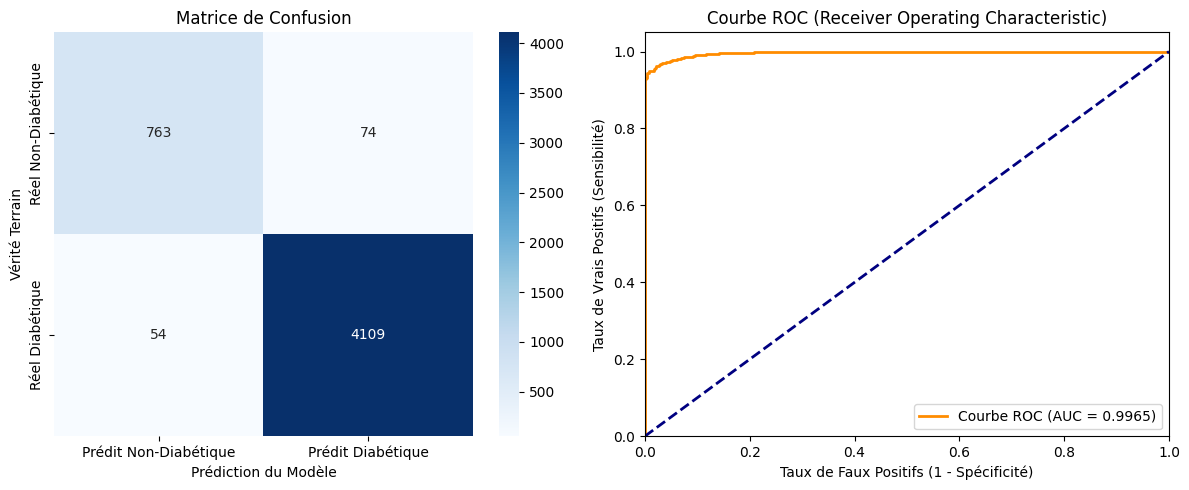

In [11]:
# Visualisation de la Matrice de Confusion et de la Courbe ROC mise à jour
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prédit Non-Diabétique', 'Prédit Diabétique'],
            yticklabels=['Réel Non-Diabétique', 'Réel Diabétique'])
plt.title('Matrice de Confusion')
plt.ylabel('Vérité Terrain')
plt.xlabel('Prédiction du Modèle')

# Visualisation de la Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test_encoded, y_pred_proba)
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Courbe ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité)")
plt.ylabel("Taux de Vrais Positifs (Sensibilité)")
plt.title('Courbe ROC (Receiver Operating Characteristic)')
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

### 📘 Interprétation Normative et Statistique des Résultats

Voici comment analyser ces résultats selon les standards de la recherche biomédicale et de la science des données :

#### 1. L'Exactitude (Accuracy)
* **Définition** : Proportion totale de prédictions correctes (vrais positifs + vrais négatifs) sur l'ensemble des prédictions.
* **Norme** : Bien que facile à comprendre, l'exactitude peut être trompeuse si le jeu de données est déséquilibré (par exemple, s'il y a 90% de personnes saines). Elle doit toujours être analysée en combinaison avec la sensibilité et la spécificité.

#### 2. La Sensibilité (Recall / True Positive Rate)
* **Définition** : Proportion de personnes réellement diabétiques que le modèle a correctement identifiées.
* **Norme en Médecine** : Dans un contexte médical, **la sensibilité est souvent la métrique la plus cruciale**. Un faux négatif (ne pas détecter un diabétique) peut empêcher le patient de recevoir son traitement, ce qui est dangereux. On cherche généralement une sensibilité très élevée (> 80-90%).

#### 3. La Spécificité (True Negative Rate)
* **Définition** : Proportion de personnes saines (non-diabétiques) que le modèle a correctement identifiées comme telles.
* **Norme** : Une faible spécificité génère des "faux positifs" (diagnostiquer à tort une personne saine comme diabétique). Bien que cela génère du stress et des examens complémentaires inutiles pour le patient, c'est généralement considéré comme moins grave qu'un faux négatif.

#### 4. Le F1-Score
* **Définition** : Moyenne harmonique entre la Précision et la Sensibilité.
* **Norme** : C'est la mesure de référence pour évaluer la performance globale sur des classes déséquilibrées. Un F1-Score proche de 1 indique un excellent équilibre sans compromettre l'une des métriques au profit de l'autre.

#### 5. L'AUC-ROC (Area Under the Curve)
* **Interprétation standard** :
  - **AUC = 0.5** : Modèle équivalent à un choix aléatoire (pile ou face).
  - **0.7 ≤ AUC < 0.8** : Performance acceptable.
  - **0.8 ≤ AUC < 0.9** : Excellente performance.
  - **AUC ≥ 0.9** : Performance exceptionnelle, très rare et hautement prédictive.
* **Norme** : L'AUC mesure la capacité du modèle à classer un patient diabétique choisi au hasard plus haut qu'un patient sain.

### 🌲 Introduction d'un Deuxième Modèle : Forêt Aléatoire (Random Forest)

Pour mener à bien notre **évaluation comparative**, nous introduisons un algorithme basé sur des arbres de décision : le **Random Forest Classifier**. Cet algorithme non-linéaire permet souvent de capter des relations plus complexes entre les variables biologiques et le diagnostic.

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Définir le pipeline complet avec le Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Entraîner le modèle
rf_pipeline.fit(X_train, y_train)
print("Modèle Random Forest entraîné avec succès !")

Modèle Random Forest entraîné avec succès !


### 📊 Évaluation du Modèle Random Forest

Calculons les mêmes métriques d'évaluation pour le Random Forest afin de pouvoir réaliser une comparaison rigoureuse.

In [14]:
# Prédictions avec Random Forest
y_pred_rf = rf_pipeline.predict(X_test)
y_pred_proba_rf = rf_pipeline.predict_proba(X_test)[:, list(rf_pipeline.classes_).index('Diabetic')]

# Métriques de base pour Random Forest
accuracy_rf = accuracy_score(y_test, y_pred_rf)
conf_matrix_rf = confusion_matrix(y_test, y_pred_rf, labels=['Non-diabetic', 'Diabetic'])
auc_score_rf = roc_auc_score(y_test_encoded, y_pred_proba_rf)

tn_rf, fp_rf, fn_rf, tp_rf = conf_matrix_rf.ravel()
sensitivity_rf = tp_rf / (tp_rf + fn_rf)
specificity_rf = tn_rf / (tn_rf + fp_rf)

print(f"=== RAPPORT DE PERFORMANCE RANDOM FOREST ===\n")
print(f"Précision globale (Accuracy) : {accuracy_rf:.4f} ({accuracy_rf*100:.2f}%)")
print(f"Sensibilité (Recall / TPR) : {sensitivity_rf:.4f} ({sensitivity_rf*100:.2f}%)")
print(f"Spécificité (TNR)           : {specificity_rf:.4f} ({specificity_rf*100:.2f}%)")
print(f"Aire sous la courbe (AUC)  : {auc_score_rf:.4f}\n")

=== RAPPORT DE PERFORMANCE RANDOM FOREST ===

Précision globale (Accuracy) : 0.9718 (97.18%)
Sensibilité (Recall / TPR) : 0.9885 (98.85%)
Spécificité (TNR)           : 0.8889 (88.89%)
Aire sous la courbe (AUC)  : 0.9948



### 📈 Tableau de Comparaison des Modèles de Classification

Voici le tableau de synthèse comparant les performances des deux modèles de classification supervisée selon les standards statistiques.

In [15]:
# Création d'un DataFrame de comparaison
comparison_df = pd.DataFrame({
    'Métrique': ['Exactitude (Accuracy)', 'Sensibilité (Sensitivity / Recall)', 'Spécificité (Specificity)', 'AUC-ROC'],
    'Régression Logistique': [accuracy, sensitivity, specificity, auc_score],
    'Random Forest': [accuracy_rf, sensitivity_rf, specificity_rf, auc_score_rf]
})

# Formater les résultats pour un affichage propre
for col in ['Régression Logistique', 'Random Forest']:
    comparison_df[col] = comparison_df[col].map(lambda x: f"{x:.4f} ({x*100:.2f}%)" if x <= 1.0 and col != 'AUC-ROC' else f"{x:.4f}")

display(comparison_df)

,Métrique,Régression Logistique,Random Forest
0,Exactitude (Accuracy),0.9744 (97.44%),0.9718 (97.18%)
1,Sensibilité (Sensitivity / Recall),0.9870 (98.70%),0.9885 (98.85%)
2,Spécificité (Specificity),0.9116 (91.16%),0.8889 (88.89%)
3,AUC-ROC,0.9965 (99.65%),0.9948 (99.48%)
